# Football match-history transformer
**Dara Heaphy and Tiernan Scully · Advanced AI · Track 3.3**

Does fixed sinusoidal positional encoding improve home/draw/away probability prediction compared with the same transformer without positions?

This notebook explains the existing experiment. It imports `dataset.py`, `audit.py` and `model.py`, and reads the recorded six-run evidence. **Run All does not retrain models, choose a new checkpoint or change any test result.** All six learning curves and confusion matrices are available from the compact `results/notebook_evidence.json`, even without the ignored `runs/` folder.

Walkthrough: data audit → one example → chronological split → model and parameters → training curves → all six results → class errors → limitations.


## 1 Setup and evidence checks
Use Python 3.11 and install `requirements-notebook.txt`. Run cells from the top. The first cell finds the project root, checks the source/data hashes against the recorded experiment and defines small display helpers. These checks catch stale results after source changes.


In [1]:
from pathlib import Path
import csv
import hashlib
import html
import json
import statistics
import sys

import numpy as np
import matplotlib.pyplot as plt
import torch
from IPython import get_ipython
from IPython.display import HTML, Markdown, display

# Register the inline image formatter before the first plot is created.
get_ipython().run_line_magic('matplotlib', 'inline')

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'model.py').is_file() and (p / 'results/config.json').is_file()), None)
if ROOT is None:
    raise RuntimeError('Open the notebook from this repository or its notebooks folder.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from audit import audit_data
from dataset import LABELS, load_datasets
from model import MatchTransformer

def read_json(relative):
    return json.loads((ROOT / relative).read_text(encoding='utf-8'))

def sha256(relative):
    return hashlib.sha256((ROOT / relative).read_bytes()).hexdigest()

def show_table(headers, rows):
    head = ''.join(f'<th style="text-align:left;padding:6px 12px">{html.escape(str(h))}</th>' for h in headers)
    body = ''.join('<tr>' + ''.join(f'<td style="text-align:left;padding:6px 12px">{html.escape(str(v))}</td>'
                                  for v in row) + '</tr>' for row in rows)
    display(HTML(f'<table><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>'))

config = read_json('results/config.json')
metrics = read_json('results/metrics.json')
evidence = read_json('results/notebook_evidence.json')
with (ROOT / 'results/individual_runs.csv').open(newline='') as f:
    rows = [{**r, 'seed': int(r['seed']), 'selected_epoch': int(r['selected_epoch']),
             **{k: float(r[k]) for k in ['validation_log_loss', 'test_log_loss', 'test_accuracy']}}
            for r in csv.DictReader(f)]
assert sha256('dataset/matches.csv') == config['data_sha256'] == evidence['data_sha256']
for filename, expected in config['source_sha256'].items():
    assert sha256(filename) == expected == evidence['source_sha256'][filename], filename
expected_grid = {(c, s) for c in ['none', 'sinusoidal'] for s in [42, 43, 44]}
assert len(rows) == 6 and {(r['condition'], r['seed']) for r in rows} == expected_grid
assert len(evidence['runs']) == 6
assert {(r['condition'], r['seed']) for r in evidence['runs']} == expected_grid
torch.set_num_threads(1)
plt.rcParams.update({'figure.dpi': 100, 'savefig.dpi': 110, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
COLORS = {'none': '#285b8a', 'sinusoidal': '#168579'}
print(f'Python {sys.version.split()[0]}, PyTorch {torch.__version__}')
print('Source and data match the recorded experiment. Two conditions × three paired seeds.')


Python 3.11.5, PyTorch 2.6.0+cpu
Source and data match the recorded experiment. Two conditions × three paired seeds.


## 2 Audit and preprocessing
The original CSV stays unchanged. The loader removes two abandoned records and ten duplicate records. We exclude the entire incomplete 2021–22 season **before constructing histories**. The audit checks seasonal fixture pairings, dates, history lengths and missing-season resets. It does not independently establish that every score matches ESPN.

Histories contain only earlier UTC dates. A team missing a Premier League season loses its previous history, preventing stale returning-team inputs such as Leeds results from 2004 entering 2020 examples. We require ten real matches per team and use no padding or feature scaling.


In [2]:
datasets = load_datasets()
audit = audit_data()
report = datasets['train'].report
saved_audit = read_json('results/data_audit.json')
# JSON stores tuple-valued missing fixture pairs as lists. Compare the same representation.
assert json.loads(json.dumps(audit)) == saved_audit, 'The current audit differs from the recorded audit.'
assert audit['passed']
show_table(['Preparation step', 'Fixtures / rows'], [
    ('Raw CSV rows', report['raw_rows']),
    ('Abandoned rows removed', report['excluded_non_completed']),
    ('Duplicate rows removed', report['excluded_duplicate_rows']),
    ('Unique completed fixtures', report['unique_completed_fixtures']),
    ('Incomplete 2021–22 fixtures excluded', report['excluded_season_fixtures']),
    ('Included complete-season fixtures', report['included_completed_fixtures']),
])
splits = ['train', 'val', 'test']
show_table(['Split', 'Source fixtures', 'Eligible', 'Short-history exclusions', 'Max history age (days)'], [
    (s, report['splits'][s]['completed_fixtures'], len(datasets[s]),
     report['splits'][s]['skipped_insufficient_history'], audit['history_ages'][s]['maximum_history_age_days'])
    for s in splits
])


Preparation step,Fixtures / rows
Raw CSV rows,7979
Abandoned rows removed,2
Duplicate rows removed,10
Unique completed fixtures,7967
Incomplete 2021–22 fixtures excluded,367
Included complete-season fixtures,7600


Split,Source fixtures,Eligible,Short-history exclusions,Max history age (days)
train,6840,6253,587,183
val,380,351,29,176
test,380,352,28,197


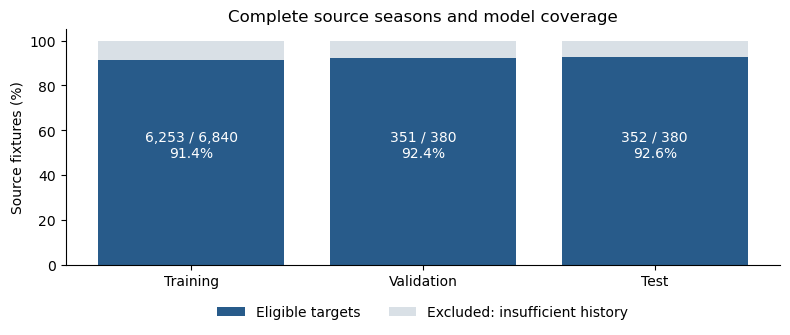

In [3]:
source = np.array([report['splits'][s]['completed_fixtures'] for s in splits])
eligible = np.array([len(datasets[s]) for s in splits])
fig, ax = plt.subplots(figsize=(8, 3.5))
x = np.arange(3)
ax.bar(x, eligible / source * 100, color=COLORS['none'], label='Eligible targets')
ax.bar(x, (source - eligible) / source * 100, bottom=eligible/source*100,
       color='#d9e0e6', label='Excluded: insufficient history')
for i in x:
    ax.text(i, 48, f'{eligible[i]:,} / {source[i]:,}\n{eligible[i]/source[i]:.1%}', ha='center', color='white')
ax.set(xticks=x, xticklabels=['Training', 'Validation', 'Test'], ylim=(0, 105),
       ylabel='Source fixtures (%)', title='Complete source seasons and model coverage')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)
fig.tight_layout()
plt.show()


**What to say:** “The test source has all 380 fixtures, but only 352 have ten valid earlier results for both teams. Source completeness and model coverage are different.”

The plot also shows a limitation: exclusions disproportionately affect early fixtures involving promoted teams. The audit checks every selected example, rather than only the example displayed below.


## 3 One real input example
We use the first validation example, not a hand-picked successful test prediction. Each row is `[goals scored, goals conceded, played at home]` from the named team's perspective. Histories run oldest to newest. Team names and dates are audit metadata, not model features.


In [4]:
example = datasets['val'].metadata[0]
home_input, away_input, target = datasets['val'][0]
fixture = example.target
print(f'{fixture.kickoff.date()}: {fixture.home} vs {fixture.away}')
print(f'Actual result: {fixture.home_score}–{fixture.away_score} ({LABELS[target.item()]})')
print(f'Input shapes: home {tuple(home_input.shape)}, away {tuple(away_input.shape)}')
for team, history in [(fixture.home, example.home_history), (fixture.away, example.away_history)]:
    assert len(history) == 10
    assert all(h.kickoff.date() < fixture.kickoff.date() for h in history)
    display(Markdown(f'### {team}'))
    show_table(['Position', 'Date', 'Fixture', 'Historical score', 'Team feature row'], [
        (i, h.kickoff.date(), f'{h.home} vs {h.away}', f'{h.home_score}–{h.away_score}', h.features_for(team))
        for i, h in enumerate(history)
    ])


2019-08-10: West Ham United vs Manchester City
Actual result: 0–5 (away_win)
Input shapes: home (10, 3), away (10, 3)


### West Ham United

Position,Date,Fixture,Historical score,Team feature row
0,2019-03-02,West Ham United vs Newcastle United,2–0,"[2, 0, 1]"
1,2019-03-09,Cardiff City vs West Ham United,2–0,"[0, 2, 0]"
2,2019-03-16,West Ham United vs Huddersfield Town,4–3,"[4, 3, 1]"
3,2019-03-30,West Ham United vs Everton,0–2,"[0, 2, 1]"
4,2019-04-08,Chelsea vs West Ham United,2–0,"[0, 2, 0]"
5,2019-04-13,Manchester United vs West Ham United,2–1,"[1, 2, 0]"
6,2019-04-20,West Ham United vs Leicester City,2–2,"[2, 2, 1]"
7,2019-04-27,Tottenham Hotspur vs West Ham United,0–1,"[1, 0, 0]"
8,2019-05-04,West Ham United vs Southampton,3–0,"[3, 0, 1]"
9,2019-05-12,Watford vs West Ham United,1–4,"[4, 1, 0]"


### Manchester City

Position,Date,Fixture,Historical score,Team feature row
0,2019-03-02,AFC Bournemouth vs Manchester City,0–1,"[1, 0, 0]"
1,2019-03-09,Manchester City vs Watford,3–1,"[3, 1, 1]"
2,2019-03-30,Fulham vs Manchester City,0–2,"[2, 0, 0]"
3,2019-04-03,Manchester City vs Cardiff City,2–0,"[2, 0, 1]"
4,2019-04-14,Crystal Palace vs Manchester City,1–3,"[3, 1, 0]"
5,2019-04-20,Manchester City vs Tottenham Hotspur,1–0,"[1, 0, 1]"
6,2019-04-24,Manchester United vs Manchester City,0–2,"[2, 0, 0]"
7,2019-04-28,Burnley vs Manchester City,0–1,"[1, 0, 0]"
8,2019-05-06,Manchester City vs Leicester City,1–0,"[1, 0, 1]"
9,2019-05-12,Brighton & Hove Albion vs Manchester City,1–4,"[4, 1, 0]"


## 4 Chronological split
Training fits weights using 2001–02 through 2018–19. Validation on 2019–20 selects an epoch independently within each run. Frozen checkpoints produce the reported 2020–21 evaluation. No 2021–22 result enters any target or input.

Earlier completed evaluation matches can enter later histories with frozen weights. This is sequential pre-match prediction, not a forecast of all fixtures before the season begins.


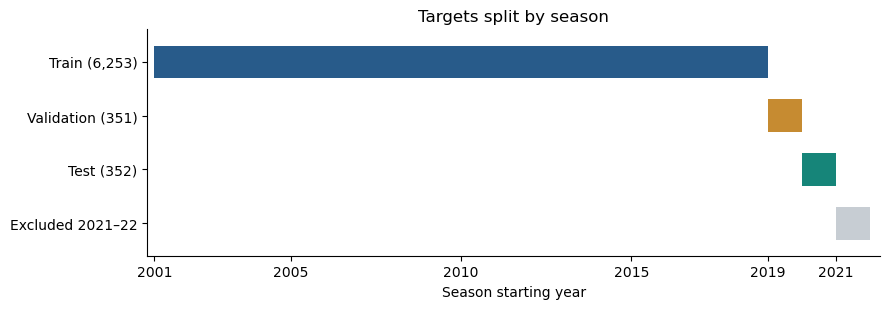

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.2))
segments = [(2001, 18, 3, COLORS['none']), (2019, 1, 2, '#c68b31'),
            (2020, 1, 1, COLORS['sinusoidal']), (2021, 1, 0, '#c7cdd3')]
for start, width, lane, color in segments:
    ax.broken_barh([(start, width)], (lane - 0.3, 0.6), facecolors=color)
ax.set(xlim=(2000.8, 2022.3), ylim=(-0.6, 3.6), yticks=[3, 2, 1, 0],
       yticklabels=['Train (6,253)', 'Validation (351)', 'Test (352)', 'Excluded 2021–22'],
       xlabel='Season starting year', xticks=[2001, 2005, 2010, 2015, 2019, 2021],
       title='Targets split by season')
fig.tight_layout()
plt.show()


## 5 Model and forward pass
`B` means batch size: the number of target fixtures processed together. Each team supplies `B × 10 × 3` values. A shared projection and one transformer encoder layer turn each history into a 32-number summary. Joining the home and away summaries gives 64 numbers, and a linear classifier produces three logits.

Two heads split width 32 into sixteen channels per head. The layer includes a 32→64→32 ReLU feedforward network, residual connections, post-layer normalisation and dropout 0.1. Each team's attention stays within its own history. There is no cross-attention between teams. All historical inputs precede the target, so no causal mask is necessary.


In [6]:
# A fresh model is sufficient to check shapes. These are NOT trained performance predictions.
torch.manual_seed(42)
shape_model = MatchTransformer('none').eval()
home_batch, away_batch = home_input.unsqueeze(0), away_input.unsqueeze(0)
with torch.no_grad():
    projected = shape_model.projection(home_batch)
    contextual = shape_model.encoder(projected)
    home_summary = shape_model.encode_team(home_batch)
    away_summary = shape_model.encode_team(away_batch)
    joined = torch.cat((home_summary, away_summary), dim=1)
    logits = shape_model(home_batch, away_batch)
show_table(['Stage', 'Shape for B = 1'], [
    ('One team input', tuple(home_batch.shape)), ('Projection', tuple(projected.shape)),
    ('Encoder output', tuple(contextual.shape)), ('Team summary', tuple(home_summary.shape)),
    ('Joined summaries', tuple(joined.shape)), ('Three outcome logits', tuple(logits.shape))
])
assert logits.shape == (1, 3)
assert sum(p.numel() for p in shape_model.parameters() if p.requires_grad) == 8867


Stage,Shape for B = 1
One team input,"(1, 10, 3)"
Projection,"(1, 10, 32)"
Encoder output,"(1, 10, 32)"
Team summary,"(1, 32)"
Joined summaries,"(1, 64)"
Three outcome logits,"(1, 3)"


### Parameter count
Parameters are learned scalar weights and biases. Width, history length and head count are hyperparameters. Both teams call the same encoder, so we count its weights once. Fixed sinusoidal positions contain 320 values, but add zero learned parameters. These dimensions were pragmatic small-study choices, not proven optima.


In [7]:
components = [
    ('Input projection', sum(p.numel() for p in shape_model.projection.parameters())),
    ('Attention Q/K/V', shape_model.encoder.self_attn.in_proj_weight.numel()
                      + shape_model.encoder.self_attn.in_proj_bias.numel()),
    ('Attention output', sum(p.numel() for p in shape_model.encoder.self_attn.out_proj.parameters())),
    ('Feedforward', sum(p.numel() for layer in [shape_model.encoder.linear1, shape_model.encoder.linear2]
                        for p in layer.parameters())),
    ('Two layer normalisations', sum(p.numel() for layer in [shape_model.encoder.norm1, shape_model.encoder.norm2]
                                     for p in layer.parameters())),
    ('Outcome classifier', sum(p.numel() for p in shape_model.classifier.parameters())),
]
show_table(['Component', 'Learned scalar count'], components + [('Total', sum(n for _, n in components))])
assert sum(n for _, n in components) == 8867
print(f'Fixed position buffer: {shape_model.positions.numel()} values; requires_grad={shape_model.positions.requires_grad}')


Component,Learned scalar count
Input projection,128
Attention Q/K/V,3168
Attention output,1056
Feedforward,4192
Two layer normalisations,128
Outcome classifier,195
Total,8867


Fixed position buffer: 320 values; requires_grad=False


### What positional encoding changes
Without positions, reordering the ten rows reorders the encoder output, but mean pooling leaves the final prediction unchanged in evaluation mode. The model still uses match content. With sinusoidal positions, each slot gets a distinct fixed vector, so order can affect the computation. That does not guarantee a performance improvement.


No-position model: reversing both histories preserves logits within numerical tolerance.
Both conditions have 8,867 learned scalars; the sinusoidal condition adds the fixed buffer.


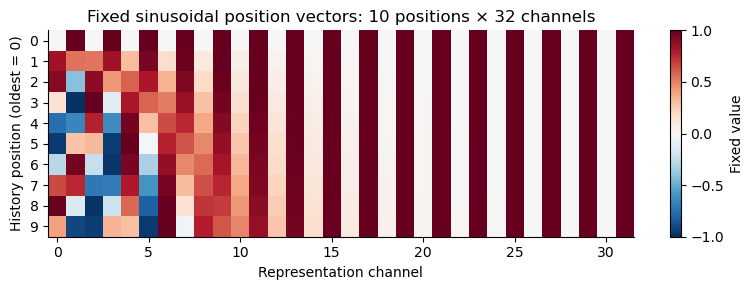

In [8]:
torch.manual_seed(42)
position_model = MatchTransformer('sinusoidal').eval()
for a, b in zip(shape_model.parameters(), position_model.parameters()):
    assert torch.equal(a, b), 'The demonstration should start with identical learned weights.'
with torch.no_grad():
    original = shape_model(home_batch, away_batch)
    reordered = shape_model(home_batch.flip(1), away_batch.flip(1))
torch.testing.assert_close(original, reordered, atol=1e-6, rtol=1e-5)
print('No-position model: reversing both histories preserves logits within numerical tolerance.')
print('Both conditions have 8,867 learned scalars; the sinusoidal condition adds the fixed buffer.')
fig, ax = plt.subplots(figsize=(8, 3))
im = ax.imshow(position_model.positions[0].numpy(), aspect='auto', cmap='RdBu_r', vmin=-1, vmax=1)
ax.set(xlabel='Representation channel', ylabel='History position (oldest = 0)',
       title='Fixed sinusoidal position vectors: 10 positions × 32 channels', yticks=range(10))
fig.colorbar(im, ax=ax, label='Fixed value')
fig.tight_layout()
plt.show()


## 6 Training and checkpoint selection
All six runs train from scratch with Adam at 0.001, batches of 32, and ten epochs. Seeds 42, 43 and 44 are paired across conditions. We use logits directly in cross-entropy. Each run retains its lowest-validation-log-loss checkpoint. We do not stop training early, choose the best seed, ensemble the runs, or select an epoch from the test curve.

The following are the recorded per-epoch learning curves from the existing runs. Training loss averages losses during weight updates with dropout on. Validation loss uses a fixed end-of-epoch model with dropout off. They therefore differ in measurement conditions as well as examples. Lower validation loss than training loss is possible.


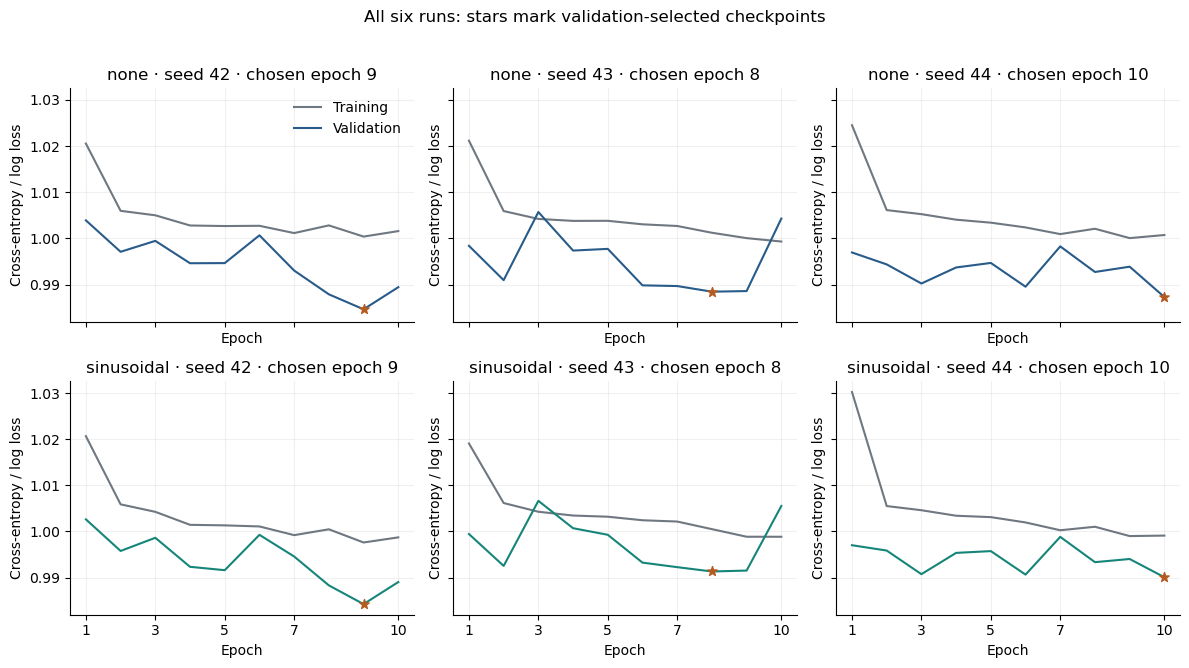

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5), sharex=True, sharey=True)
for item in evidence['runs']:
    row = 0 if item['condition'] == 'none' else 1
    col = [42, 43, 44].index(item['seed'])
    ax = axes[row, col]
    curve = item['learning_curve']
    selected = min(curve, key=lambda p: p['validation_log_loss'])
    assert selected['epoch'] == item['selected_epoch']
    recorded = next(r for r in rows if r['condition'] == item['condition'] and r['seed'] == item['seed'])
    assert abs(selected['validation_log_loss'] - recorded['validation_log_loss']) < 1e-12
    ax.plot([p['epoch'] for p in curve], [p['training_loss'] for p in curve], label='Training', color='#6f7780')
    ax.plot([p['epoch'] for p in curve], [p['validation_log_loss'] for p in curve],
            label='Validation', color=COLORS[item['condition']])
    ax.scatter(selected['epoch'], selected['validation_log_loss'], s=50, marker='*', color='#b45b22', zorder=5)
    ax.set(title=f"{item['condition']} · seed {item['seed']} · chosen epoch {item['selected_epoch']}",
           xticks=[1, 3, 5, 7, 10], xlabel='Epoch', ylabel='Cross-entropy / log loss')
    ax.grid(alpha=0.18)
axes[0, 0].legend(frameon=False)
fig.suptitle('All six runs: stars mark validation-selected checkpoints', y=1.02)
fig.tight_layout()
plt.show()


## 7 All six results and the paired comparison
Log loss is our primary metric: it scores the probability assigned to the actual result, with larger penalties for confident mistakes. Accuracy checks only the highest-probability outcome. Brier score is secondary. The constant predictor estimates class probabilities from training frequencies only.

**Difference = sinusoidal loss − no-position loss. Negative favours positions.** The two conditions use the same fixtures within each comparison. Seed variation describes optimisation randomness on this dataset, not uncertainty across future seasons.


Condition,Seed,Selected epoch,Validation loss,Test loss,Test accuracy
none,42,9,0.984636,1.066951,47.44%
sinusoidal,42,9,0.984257,1.072184,46.31%
none,43,8,0.988454,1.068002,47.16%
sinusoidal,43,8,0.991329,1.066248,45.45%
none,44,10,0.987293,1.066857,44.03%
sinusoidal,44,10,0.990084,1.072594,44.89%


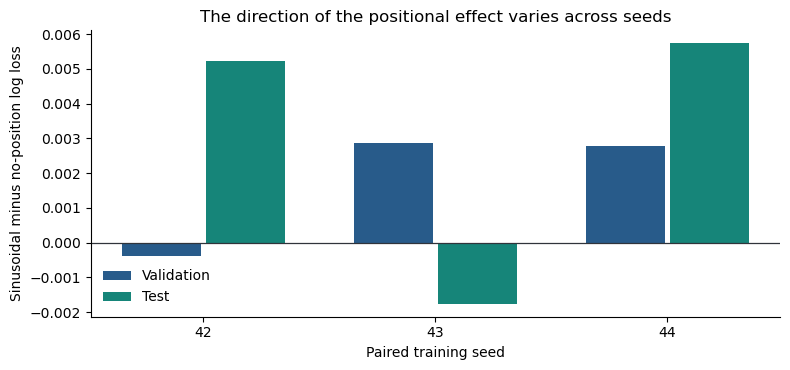

Condition,Mean test log loss,Mean accuracy
none,1.067270,46.21%
sinusoidal,1.070342,45.55%
Training-frequency baseline,1.097316,38.07%


Mean paired test difference: +0.003072
Sample SD across three paired differences: 0.004187


In [10]:
show_table(['Condition', 'Seed', 'Selected epoch', 'Validation loss', 'Test loss', 'Test accuracy'], [
    (r['condition'], r['seed'], r['selected_epoch'], f"{r['validation_log_loss']:.6f}",
     f"{r['test_log_loss']:.6f}", f"{r['test_accuracy']:.2%}") for r in rows
])
lookup = {(r['condition'], r['seed']): r for r in rows}
seeds = [42, 43, 44]
differences = {}
for split, key in [('Validation', 'validation_log_loss'), ('Test', 'test_log_loss')]:
    differences[split] = [lookup['sinusoidal', s][key] - lookup['none', s][key] for s in seeds]
assert abs(statistics.mean(differences['Test']) - metrics['test']['paired_log_loss']['mean']) < 1e-12
assert abs(statistics.stdev(differences['Test']) - metrics['test']['paired_log_loss']['sample_sd']) < 1e-12
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(3)
for split, offset, color in [('Validation', -0.18, COLORS['none']), ('Test', 0.18, COLORS['sinusoidal'])]:
    ax.bar(x + offset, differences[split], width=0.34, label=split, color=color)
ax.axhline(0, color='#30343b', linewidth=0.9)
ax.set(xticks=x, xticklabels=seeds, xlabel='Paired training seed', ylabel='Sinusoidal minus no-position log loss',
       title='The direction of the positional effect varies across seeds')
ax.legend(frameon=False)
fig.tight_layout()
plt.show()
show_table(['Condition', 'Mean test log loss', 'Mean accuracy'], [
    (c, f"{metrics['test']['conditions'][c]['log_loss']['mean']:.6f}",
     f"{metrics['test']['conditions'][c]['accuracy']['mean']:.2%}") for c in ['none', 'sinusoidal']
] + [('Training-frequency baseline', f"{metrics['test']['training_frequency_baseline']['log_loss']:.6f}",
      f"{metrics['test']['training_frequency_baseline']['accuracy']:.2%}")])
print(f"Mean paired test difference: {statistics.mean(differences['Test']):+.6f}")
print(f"Sample SD across three paired differences: {statistics.stdev(differences['Test']):.6f}")


**Interpretation:** positions improve test log loss in one of three pairs. The mean slightly favours no positions. We find no consistent benefit from this positional scheme under these settings. We have not shown statistical equivalence, that order never matters, or that a transformer outperforms stronger football models.

The no-position transformer isolates the positional change. The constant baseline is a sanity check. Beating the latter does not establish that attention is necessary.


## 8 Class errors and the draw problem
Each matrix below shows one complete test prediction set: rows are actual outcomes and columns are predicted outcomes. Showing all seeds avoids selecting the most flattering run. Matrices are **not** pooled into one supposedly independent enlarged test set.


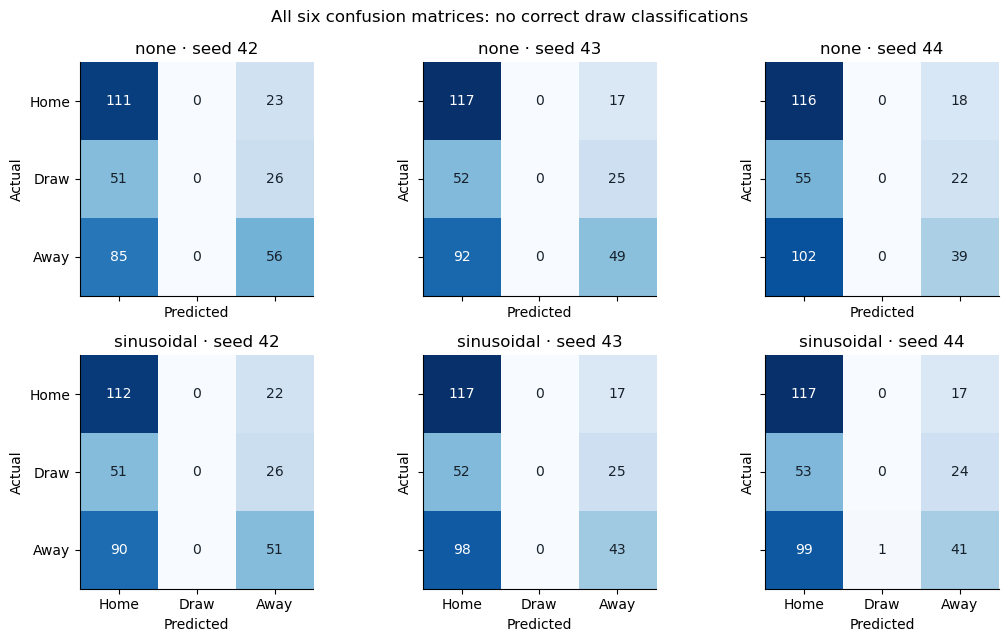

Condition,Seed,Actual draws,Predicted draws,Correct draws
none,42,77,0,0
sinusoidal,42,77,0,0
none,43,77,0,0
sinusoidal,43,77,0,0
none,44,77,0,0
sinusoidal,44,77,1,0


In [11]:
with (ROOT / 'results/class_errors.csv').open(newline='') as f:
    class_rows = list(csv.DictReader(f))
labels = ['Home', 'Draw', 'Away']
fig, axes = plt.subplots(2, 3, figsize=(11, 6.5), sharex=True, sharey=True)
vmax = max(max(max(row) for row in r['test_confusion_matrix']) for r in evidence['runs'])
draw_rows = []
for item in evidence['runs']:
    cm = np.asarray(item['test_confusion_matrix'])
    assert cm.shape == (3, 3) and cm.sum() == len(datasets['test'])
    scalar = lookup[item['condition'], item['seed']]
    assert np.isclose(np.trace(cm) / cm.sum(), scalar['test_accuracy'])
    for k, label in enumerate(LABELS):
        saved = next(r for r in class_rows if r['condition'] == item['condition']
                     and int(r['seed']) == item['seed'] and r['class'] == label)
        assert [int(saved[x]) for x in ['actual_count', 'predicted_count', 'correct_count']] == [
            int(cm[k].sum()), int(cm[:, k].sum()), int(cm[k, k])]
    draw_rows.append((item['condition'], item['seed'], int(cm[1].sum()), int(cm[:, 1].sum()), int(cm[1, 1])))
    ax = axes[0 if item['condition'] == 'none' else 1, seeds.index(item['seed'])]
    im = ax.imshow(cm, cmap='Blues', vmin=0, vmax=vmax)
    for (i, j), value in np.ndenumerate(cm):
        ax.text(j, i, str(value), ha='center', va='center', color='white' if value > vmax/2 else '#17212b')
    ax.set(xticks=range(3), yticks=range(3), xticklabels=labels, yticklabels=labels,
           xlabel='Predicted', ylabel='Actual', title=f"{item['condition']} · seed {item['seed']}")
fig.suptitle('All six confusion matrices: no correct draw classifications')
fig.tight_layout()
plt.show()
show_table(['Condition', 'Seed', 'Actual draws', 'Predicted draws', 'Correct draws'], draw_rows)


Every model correctly classifies zero of the 77 actual draws. Five predict no draws; sinusoidal seed 44 predicts one incorrectly. This does **not** mean draw probabilities are zero. Nor does it establish calibration. We did not tune thresholds or class weights after inspecting these test results.

A change in outcome frequencies is also worth investigating. The next plot compares the eligible target populations, not every source fixture. It describes the shift without assigning a cause to it.


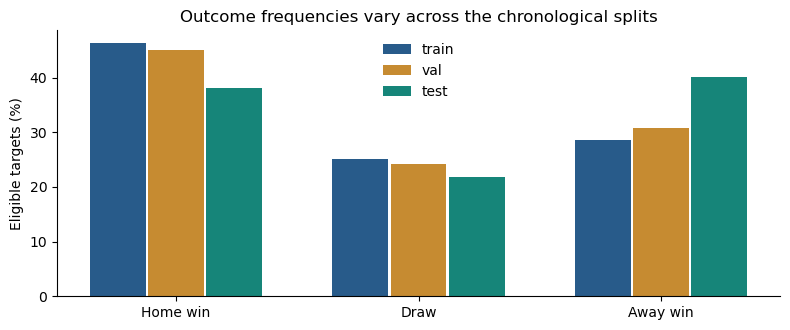

In [12]:
fig, ax = plt.subplots(figsize=(8, 3.4))
x = np.arange(3)
for split, offset, color in [('train', -0.24, COLORS['none']), ('val', 0, '#c68b31'), ('test', 0.24, COLORS['sinusoidal'])]:
    counts = np.array([report['splits'][split]['class_counts'][label] for label in LABELS])
    ax.bar(x + offset, counts / counts.sum() * 100, width=0.23, label=split, color=color)
ax.set(xticks=x, xticklabels=['Home win', 'Draw', 'Away win'], ylabel='Eligible targets (%)',
       title='Outcome frequencies vary across the chronological splits')
ax.legend(frameon=False)
fig.tight_layout()
plt.show()


## 9 One recorded trained prediction
This is the first validation fixture using the no-position seed-42 checkpoint, selected by that run's validation loss. We fix this example by index and seed rather than choosing a successful test prediction. Unlike the earlier shape demonstration, these probabilities come from a trained model.

The compact evidence preserves this saved prediction. If the original local checkpoint exists, the cell also checks its hash and recomputes the prediction using `train.load_checkpoint`. A fresh clone without ignored weights can still display the recorded example. It must reproduce the experiment to regenerate those weights.


In [13]:
item = next(r for r in evidence['runs'] if r['condition'] == 'none' and r['seed'] == 42)
prediction = item['validation_example']
assert prediction['fixture_id'] == fixture.fixture_id and prediction['index'] == 0
assert prediction['label'] == target.item()
probabilities = np.array([prediction['probabilities'][label] for label in LABELS])
assert np.isclose(probabilities.sum(), 1.0) and np.all(probabilities >= 0)
checkpoint = ROOT / item['run_dir'] / 'best.pt'
if checkpoint.exists():
    from train import load_checkpoint
    assert sha256(checkpoint.relative_to(ROOT)) == item['checkpoint_sha256']
    trained_model, _ = load_checkpoint(checkpoint)
    with torch.no_grad():
        actual = trained_model(home_batch, away_batch).softmax(dim=1)[0].numpy()
    np.testing.assert_allclose(actual, probabilities, rtol=1e-6, atol=1e-7)
    print('Local checkpoint verified: prediction reproduced.')
else:
    print('Recorded validation prediction shown; local weights are not present.')
show_table(['Outcome', 'Recorded probability'], [(label, f'{p:.2%}') for label, p in zip(LABELS, probabilities)])
print(f"Fixture: {prediction['home']} vs {prediction['away']}; actual outcome: {prediction['label_name']}")
print('One example explains the interface. It does not establish generalisation.')


Local checkpoint verified: prediction reproduced.


Outcome,Recorded probability
home_win,15.37%
draw,17.85%
away_win,66.79%


Fixture: West Ham United vs Manchester City; actual outcome: away_win
One example explains the interface. It does not establish generalisation.


## 10 Conclusion and interview discussion

**Finding:** no consistent benefit from fixed sinusoidal positions across three paired seeds. We retain all six runs and show the class-level weaknesses.

**Limits that affect the claim**
- One evaluation season and three seeds give limited evidence. Shared teams and overlapping histories make fixtures dependent.
- Sufficient-history filtering excludes some early promoted-team fixtures.
- Inputs omit opponent strength, squad changes and elapsed time. The classifier combines team summaries linearly, without a further nonlinear joint interaction.
- Zero draw recall is a substantial classification weakness. Constant-prior improvement does not prove transformer superiority or betting value.

**Next experiment:** obtain genuinely unseen complete seasons, freeze the protocol and compare against a stronger simple baseline before making broader claims. Additional modelling choices should use training/validation evidence, not repeated optimisation against these test results.
An alternative dataset would definitely be considered also. 
